In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
import pandas as pd
import numpy as np
%matplotlib inline

In [2]:
X,y=make_blobs(n_samples=1000,centers=3,n_features=2)

In [3]:
X

array([[ 2.02716185,  6.75401251],
       [-5.36630481,  0.08572319],
       [-5.79094562,  0.97393245],
       ...,
       [-5.56497666,  0.3685667 ],
       [ 1.46883341,  8.16457882],
       [-9.56597111,  3.95860566]], shape=(1000, 2))

In [4]:
y

array([0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 2, 0, 1, 1, 2, 1, 2, 1, 0,
       2, 2, 2, 1, 0, 2, 0, 0, 0, 0, 0, 1, 2, 0, 1, 0, 2, 0, 1, 1, 0, 0,
       2, 1, 2, 1, 0, 1, 2, 0, 2, 0, 0, 0, 1, 2, 1, 2, 2, 2, 2, 1, 2, 2,
       1, 1, 0, 2, 0, 0, 1, 2, 2, 2, 1, 1, 2, 1, 0, 2, 2, 2, 1, 1, 2, 0,
       0, 0, 0, 1, 2, 0, 2, 1, 0, 2, 2, 0, 1, 0, 0, 2, 2, 1, 1, 2, 1, 0,
       0, 1, 1, 1, 0, 2, 2, 0, 0, 0, 1, 2, 0, 0, 1, 1, 0, 2, 1, 1, 1, 2,
       0, 1, 1, 1, 1, 0, 0, 2, 2, 0, 2, 0, 2, 2, 0, 2, 0, 1, 1, 2, 0, 1,
       2, 0, 0, 1, 2, 1, 2, 2, 2, 0, 2, 0, 1, 1, 0, 2, 0, 1, 2, 2, 0, 1,
       1, 1, 0, 1, 1, 2, 0, 1, 1, 0, 0, 1, 1, 0, 2, 0, 1, 2, 2, 2, 0, 2,
       1, 2, 0, 1, 2, 0, 1, 2, 2, 2, 2, 2, 0, 0, 2, 2, 2, 1, 1, 1, 2, 2,
       1, 2, 0, 1, 0, 0, 1, 0, 1, 0, 1, 2, 0, 2, 2, 2, 0, 2, 1, 2, 2, 2,
       2, 0, 1, 2, 1, 2, 2, 0, 1, 2, 2, 0, 2, 2, 1, 0, 1, 0, 1, 1, 1, 1,
       1, 1, 0, 2, 1, 1, 1, 1, 0, 1, 1, 2, 1, 0, 2, 0, 1, 2, 0, 1, 0, 2,
       1, 1, 2, 0, 2, 1, 0, 0, 1, 1, 2, 2, 2, 0, 1,

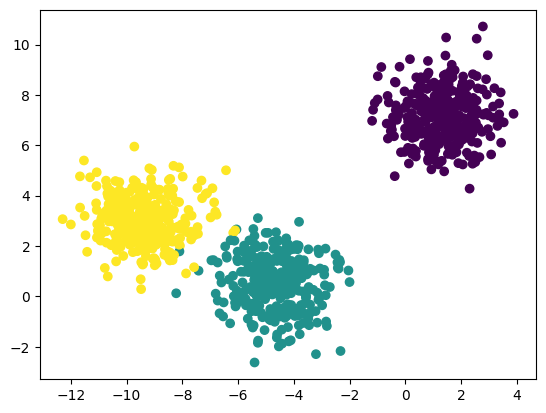

In [5]:
plt.scatter(X[:,0],X[:,1],c=y)

In [6]:
#standardization--feature scaling technique
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

In [7]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.33,random_state=42
    )

In [8]:
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [9]:
from sklearn.cluster import KMeans

In [10]:
wcss=[]
for k in range(1,11):
    kmeans=KMeans(n_clusters=k,init="k-means++")
    kmeans.fit(X_train_scaled)
    wcss.append(kmeans.inertia_)

In [11]:
wcss

[1339.9999999999995,
 319.9374090115499,
 106.78720045696575,
 90.13749987691446,
 72.20556495079566,
 69.5424848922969,
 64.43403138502836,
 47.165605425662676,
 43.66918220264567,
 39.198259366339265]

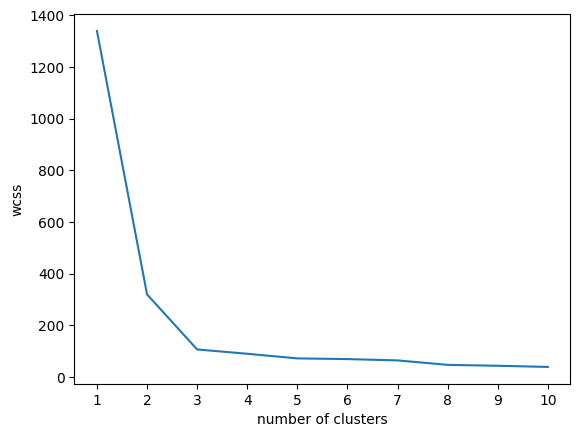

In [12]:
#plot elbow curve
plt.plot(range(1,11),wcss)
plt.xticks(range(1,11))
plt.xlabel("number of clusters")
plt.ylabel("wcss")
plt.show()

In [13]:
kmeans=KMeans(n_clusters=3,init="k-means++")

In [15]:
kmeans.fit_predict(X_train_scaled)

array([2, 0, 1, 2, 1, 2, 2, 0, 0, 2, 2, 2, 0, 2, 0, 0, 0, 1, 1, 0, 0, 2,
       0, 0, 2, 0, 2, 2, 1, 0, 1, 1, 2, 1, 0, 1, 2, 0, 0, 0, 0, 0, 0, 0,
       1, 1, 1, 0, 1, 0, 2, 0, 1, 0, 2, 2, 0, 1, 1, 0, 1, 2, 2, 2, 1, 2,
       2, 0, 1, 2, 0, 2, 0, 2, 0, 0, 1, 1, 1, 0, 1, 0, 1, 2, 1, 0, 2, 0,
       2, 2, 2, 0, 1, 2, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 2, 2, 2,
       2, 0, 2, 1, 0, 0, 1, 2, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 2,
       0, 1, 1, 0, 1, 2, 2, 0, 0, 0, 2, 1, 0, 2, 0, 0, 2, 0, 2, 0, 2, 1,
       1, 1, 1, 2, 2, 2, 1, 2, 1, 2, 2, 1, 1, 2, 0, 0, 1, 2, 1, 2, 2, 1,
       2, 2, 0, 0, 1, 0, 1, 2, 2, 1, 1, 2, 0, 0, 0, 2, 0, 2, 2, 1, 1, 1,
       0, 1, 0, 1, 1, 1, 1, 1, 2, 0, 2, 2, 2, 2, 1, 2, 1, 2, 2, 0, 0, 1,
       0, 1, 2, 0, 0, 1, 1, 2, 0, 2, 0, 0, 1, 0, 2, 2, 2, 1, 1, 0, 2, 2,
       2, 0, 0, 1, 0, 2, 1, 2, 0, 0, 0, 1, 0, 0, 2, 2, 0, 2, 0, 1, 0, 2,
       2, 0, 2, 2, 1, 0, 0, 0, 2, 0, 0, 0, 0, 0, 1, 1, 2, 1, 2, 1, 0, 1,
       2, 1, 2, 2, 0, 2, 2, 2, 2, 0, 1, 2, 2, 1, 0,

In [16]:
y_pred=kmeans.predict(X_test_scaled)

In [17]:
y_pred

array([1, 0, 0, 2, 1, 0, 2, 1, 2, 2, 1, 2, 2, 0, 1, 0, 2, 0, 1, 2, 1, 1,
       1, 2, 1, 0, 1, 2, 2, 2, 2, 0, 1, 1, 2, 2, 2, 2, 0, 0, 0, 1, 2, 1,
       1, 1, 1, 1, 0, 2, 2, 0, 2, 2, 0, 1, 1, 2, 0, 1, 0, 1, 2, 0, 1, 2,
       1, 1, 1, 0, 0, 0, 2, 0, 1, 1, 1, 1, 1, 1, 0, 2, 0, 2, 2, 2, 1, 1,
       2, 0, 1, 0, 0, 0, 0, 0, 2, 1, 2, 2, 2, 0, 0, 2, 2, 2, 1, 1, 1, 1,
       1, 1, 1, 2, 0, 0, 2, 2, 0, 2, 1, 0, 2, 2, 0, 0, 1, 1, 1, 1, 0, 2,
       2, 0, 0, 1, 2, 2, 2, 2, 0, 0, 1, 0, 1, 2, 2, 2, 1, 2, 2, 0, 1, 2,
       1, 0, 1, 0, 0, 1, 2, 2, 1, 1, 2, 1, 0, 2, 1, 1, 1, 2, 1, 2, 1, 2,
       0, 1, 0, 0, 1, 2, 2, 2, 1, 1, 1, 2, 0, 2, 1, 2, 0, 0, 0, 1, 0, 0,
       2, 0, 1, 2, 2, 0, 1, 2, 1, 0, 2, 2, 0, 1, 2, 0, 1, 0, 0, 1, 0, 1,
       1, 2, 0, 2, 0, 2, 2, 1, 2, 1, 2, 1, 1, 0, 2, 1, 0, 1, 2, 1, 1, 2,
       0, 2, 1, 1, 2, 2, 2, 2, 0, 1, 1, 0, 2, 2, 0, 0, 2, 2, 1, 0, 0, 1,
       2, 1, 2, 2, 2, 0, 0, 1, 1, 2, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0,
       1, 2, 1, 2, 2, 0, 2, 0, 0, 1, 2, 2, 1, 1, 2,

In [ ]:
gf